# 04 · Full-lot demo: from patches back to a parking lot

Notebook 03 scored the model one space at a time. A real user doesn't care about patches. They want to know
**"how many spots are free right now, and where?"** This notebook runs the trained model on **whole PUCPR photos**
(the lot it never saw) and answers that question.

It also saves two pictures into `images/` for the README.

The model and the cropping code now live in **`model.py`**, so this notebook (and the demo app later) use exactly
the same preprocessing as training. Copying that code by hand is a classic source of bugs.

In [1]:
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from PIL import Image

from model import NAMES, crop_spaces, load_model, predict

device = "cuda" if torch.cuda.is_available() else "cpu"
model = load_model("small_cnn_best.pt", device)
Path("images").mkdir(exist_ok=True)
print("Model loaded on", device)

Model loaded on cuda


## 1. Collect every PUCPR photo with its labeled spaces

Same camera trick as before: PUCPR photos have exactly 100 labeled spaces.

In [2]:
pucpr = []
for split in ["train", "valid", "test"]:
    with open(f"{split}/_annotations.coco.json") as f:
        coco = json.load(f)
    spaces_by_image = defaultdict(list)
    for a in coco["annotations"]:
        spaces_by_image[a["image_id"]].append(a)
    for img in coco["images"]:
        spaces = spaces_by_image[img["id"]]
        if len(spaces) == 100:
            pucpr.append({
                "path": f"{split}/{img['file_name']}",
                "date": img["file_name"][:10],
                "time": img["file_name"][11:16].replace("_", ":"),  # e.g. 14:05
                "boxes": [s["bbox"] for s in spaces],
                "truth": torch.tensor([s["category_id"] - 1 for s in spaces]),  # 1/2 -> 0/1
            })

days = Counter(p["date"] for p in pucpr)
busiest_day, n_photos = days.most_common(1)[0]
print(f"{len(pucpr)} PUCPR photos over {len(days)} days. Busiest day: {busiest_day} ({n_photos} photos)")

4473 PUCPR photos over 37 days. Busiest day: 2012-10-11 (185 photos)


## 2. One photo, every space

- **Green** = model says empty, **red** = model says occupied
- **Thick yellow outline** = the model got that space wrong

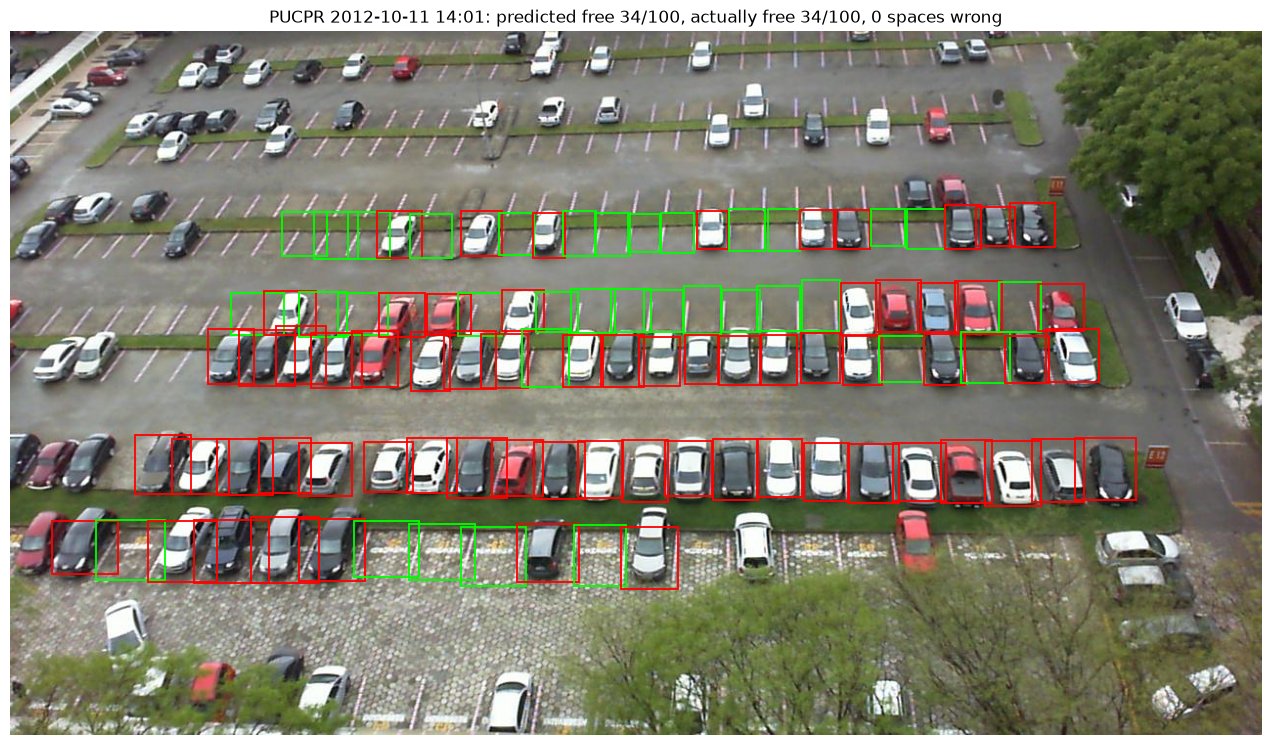

In [3]:
def run_on_photo(photo):
    image = Image.open(photo["path"]).convert("RGB")
    labels, confidence = predict(model, crop_spaces(image, photo["boxes"]), device)
    return image, labels, confidence

def draw_photo(photo, image, labels, save_as=None):
    wrong = labels != photo["truth"]
    fig, ax = plt.subplots(figsize=(13, 7.5))
    ax.imshow(image)
    for (x, y, w, h), label, is_wrong in zip(photo["boxes"], labels, wrong):
        color = "lime" if label == 0 else "red"
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=1.3))
        if is_wrong:
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor="yellow", linewidth=3.5))
    free_pred = (labels == 0).sum().item()
    free_true = (photo["truth"] == 0).sum().item()
    ax.set_title(f"PUCPR {photo['date']} {photo['time']}: predicted free {free_pred}/100, "
                 f"actually free {free_true}/100, {wrong.sum().item()} spaces wrong", fontsize=12)
    ax.axis("off")
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=110, bbox_inches="tight")
    plt.show()

# The busiest day's photo closest to 2 PM: a busy lot with a mix of free and taken spaces
day_photos = sorted([p for p in pucpr if p["date"] == busiest_day], key=lambda p: p["time"])
photo = min(day_photos, key=lambda p: abs(int(p["time"][:2]) * 60 + int(p["time"][3:]) - 14 * 60))

image, labels, confidence = run_on_photo(photo)
draw_photo(photo, image, labels, save_as="images/demo_pucpr.png")

## 3. A whole day: free spots over time

This is the feature a driver (or the parking office) would actually use. For every photo on the busiest day,
count how many spaces the model thinks are free and compare it to the true count.

Photos: 185
Average error in the free-spot count: 1.6 spots (out of 100)
Worst photo: off by 34 spots


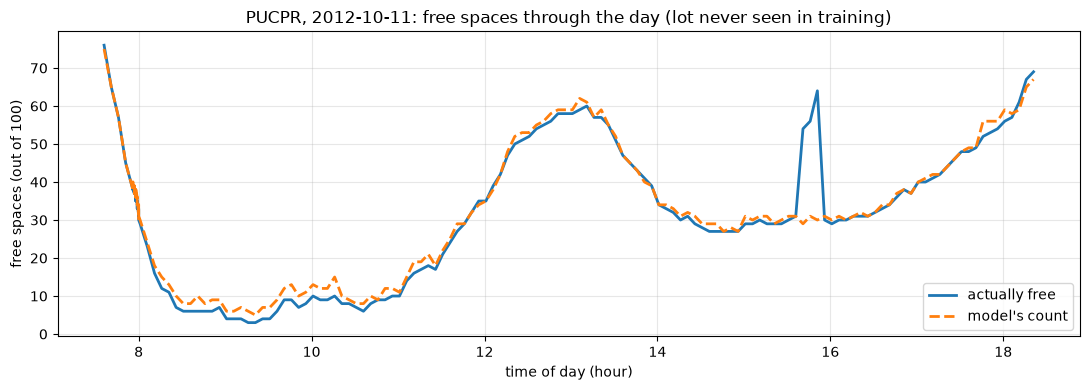

In [4]:
times, predicted_free, true_free = [], [], []
for p in day_photos:
    _, labels, _ = run_on_photo(p)
    times.append(int(p["time"][:2]) + int(p["time"][3:]) / 60)  # hours as a decimal, e.g. 14.5
    predicted_free.append((labels == 0).sum().item())
    true_free.append((p["truth"] == 0).sum().item())

errors = [abs(a - b) for a, b in zip(predicted_free, true_free)]
print(f"Photos: {len(times)}")
print(f"Average error in the free-spot count: {sum(errors) / len(errors):.1f} spots (out of 100)")
print(f"Worst photo: off by {max(errors)} spots")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(times, true_free, label="actually free", linewidth=2)
ax.plot(times, predicted_free, label="model's count", linewidth=2, linestyle="--")
ax.set_xlabel("time of day (hour)")
ax.set_ylabel("free spaces (out of 100)")
ax.set_title(f"PUCPR, {busiest_day}: free spaces through the day (lot never seen in training)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/occupancy_day.png", dpi=110, bbox_inches="tight")
plt.show()

## Takeaways (fill in after running)

- In the single photo, which spaces are wrong? Near the edges? Under shadows? Next to a parked car?
- How far off is the free-spot count on average? Is that good enough for a driver?
- Are errors worse at certain times of day (early morning, evening light)?

`images/demo_pucpr.png` and `images/occupancy_day.png` are now saved for the README.